In [ ]:

# Dependencies: numpy, pandas, matplotlib, polars, pyarrow, scipy, h3,
#               contextily, geopandas, shapely.


# Basemap tiles require internet. The key is read from CARTO_BASEMAP_API_KEY
# or the original local config file; its contents are never embedded here.
# Include this attribution when sharing the maps:
#   Basemap © OpenStreetMap contributors, © CARTO.
# Maps/histogram prefer Arial and fall back to bundled DejaVu Sans if unavailable.

import os
from pathlib import Path as FilePath

DATA_ROOT = FilePath(os.environ.get("FIGURE1_DATA_ROOT", "/home/chen/data")).expanduser()
BASE_PARQUET = DATA_ROOT / "regression/base.parquet"
MP_PARQUET = DATA_ROOT / "/MP/MP_all.parquet"

CACHE_DIR = FilePath("./.cache/figure_1_basemap")
BASEMAP_API_KEY_FILE = FilePath(os.environ.get(
    "CARTO_BASEMAP_API_KEY_FILE",
    str(FilePath.home() / ".config/meeting_network_visuals/carto_api_key"),
)).expanduser()


In [15]:

import os
import warnings
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager


FIGURE_FONT = (
    "Arial" if any(font.name == "Arial" for font in font_manager.fontManager.ttflist)
    else "DejaVu Sans"
)
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import PathPatch, Polygon
from matplotlib.path import Path
from matplotlib.lines import Line2D

import polars as pl

import h3

import contextily as ctx
import contextily.tile as ctx_tile

import geopandas as gpd
from shapely.geometry import Point, box

warnings.filterwarnings("ignore")

MM = 1 / 25.4
MAP_LEGEND_FONTSIZE = 10
BASEMAP_URL = "https://basemaps.cartocdn.com/rastertiles/light_nolabels/{z}/{x}/{y}.png"
BASEMAP_ALPHA = 0.45
BASEMAP_USER_AGENT = "MeetingNetworkVisuals/1.0 (Python research map visualization)"
BASEMAP_CACHE_DIR = str(CACHE_DIR)
plt.rcdefaults()
plt.rcParams.update({
    "font.family":       FIGURE_FONT,
    "font.size":         7,
    "axes.labelsize":    7,
    "axes.titlesize":    8,
    "xtick.labelsize":   6,
    "ytick.labelsize":   6,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  2,
    "ytick.major.size":  2,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})

DATA_PATH = str(BASE_PARQUET)

LNG_MIN, LNG_MAX = 139.59, 139.92
LAT_MIN, LAT_MAX = 35.55, 35.81

EDGE_CMAP = LinearSegmentedColormap.from_list(
    "mp_edges",
    ["#edf8fb", "#b3cde3", "#8c96c6", "#88419d", "#4d004b"],
    N=256,
)

TRANS_EDGE_CMAP = LinearSegmentedColormap.from_list(
    "transaction_edges",
    ["#edf8e9", "#bae4bc", "#7bccc4", "#2b8c8e", "#084b5a"],
    N=256,
)

NODE_CMAP = LinearSegmentedColormap.from_list(
    "mp_nodes",
    ["#fee6ce", "#fdae6b", "#e6550d", "#a63603", "#4d1600"],
    N=256,
)

TRANSACTION_LINK_COL = "n_trans_2020"

In [16]:

def polars_to_pandas(frame):
    """Convert the aggregated plot data without requiring optional pyarrow."""
    return pd.DataFrame(frame.to_dict(as_series=False))


def h3_center(cell):
    if hasattr(h3, "cell_to_latlng"):
        lat, lng = h3.cell_to_latlng(cell)
    else:
        lat, lng = h3.h3_to_geo(cell)
    return float(lng), float(lat)


def add_basemap(ax, zoom=11):
    """Draw the gray CARTO/OSM basemap without place or road labels."""
    api_key = os.environ.get("CARTO_BASEMAP_API_KEY", "").strip()
    if not api_key:
        api_key = BASEMAP_API_KEY_FILE.read_text().strip()
    source = BASEMAP_URL + "?key=" + quote(api_key, safe="")
    ctx_tile.USER_AGENT = BASEMAP_USER_AGENT
    os.makedirs(BASEMAP_CACHE_DIR, exist_ok=True)
    ctx.set_cache_dir(BASEMAP_CACHE_DIR)
    ctx.add_basemap(
        ax,
        source=source,
        crs="EPSG:3857",
        attribution=False,  # Include basemap attribution in the figure caption.
        attribution_size=4,
        zoom=zoom,
        alpha=BASEMAP_ALPHA,
        zorder=0,
    )


def project_points(pdf, lng_col="lng", lat_col="lat"):
    gdf = gpd.GeoDataFrame(
        pdf.copy(),
        geometry=[Point(xy) for xy in zip(pdf[lng_col], pdf[lat_col])],
        crs="EPSG:4326",
    ).to_crs("EPSG:3857")
    pdf = pdf.copy()
    pdf["x"] = gdf.geometry.x
    pdf["y"] = gdf.geometry.y
    return pdf


def tokyo_extent_for_axes():
    extent = gpd.GeoSeries(
        [box(LNG_MIN, LAT_MIN, LNG_MAX, LAT_MAX)],
        crs="EPSG:4326",
    ).to_crs("EPSG:3857").total_bounds
    xmin, ymin, xmax, ymax = extent
    side = max(xmax - xmin, ymax - ymin)
    xmid = 0.5 * (xmin + xmax)
    ymid = 0.5 * (ymin + ymax)
    return xmid - 0.5 * side, xmid + 0.5 * side, ymid - 0.5 * side, ymid + 0.5 * side


def add_map_annotations(ax, link_label, link_color):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    dx = xmax - xmin
    dy = ymax - ymin

    nx, ny = 0.075, 0.17
    north_arrow = Polygon(
        [
            (nx, ny + 0.045),
            (nx - 0.018, ny - 0.025),
            (nx + 0.018, ny - 0.025),
        ],
        closed=True,
        transform=ax.transAxes,
        facecolor="#1a1a1a",
        edgecolor="none",
        zorder=5,
    )
    ax.add_patch(north_arrow)
    ax.text(
        nx,
        ny + 0.062,
        "N",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=6,
        fontweight="bold",
        color="#1a1a1a",
        zorder=5,
    )

    scale_len = 5000

    sx = xmin + 0.06 * dx
    sy = ymin + 0.045 * dy
    ax.plot([sx, sx + scale_len], [sy, sy], color="#1a1a1a", lw=1.0, solid_capstyle="butt", zorder=5)
    ax.plot([sx, sx], [sy - 0.006 * dy, sy + 0.006 * dy], color="#1a1a1a", lw=0.7, zorder=5)
    ax.plot(
        [sx + scale_len, sx + scale_len],
        [sy - 0.006 * dy, sy + 0.006 * dy],
        color="#1a1a1a",
        lw=0.7,
        zorder=5,
    )
    ax.text(
        sx + 0.5 * scale_len,
        sy + 0.014 * dy,
        "5 km",
        ha="center",
        va="bottom",
        fontsize=5.5,
        color="#1a1a1a",
        zorder=5,
    )


    legend = ax.legend(
        handles=[Line2D(
            [0], [0],
            color=link_color,
            lw=1.15,
            alpha=0.75,
            solid_capstyle="round",
            label=link_label,
        )],
        loc="lower right",
        bbox_to_anchor=(0.98, 0.025),
        fontsize=MAP_LEGEND_FONTSIZE,
        frameon=False,
        handlelength=1.8,
        handletextpad=0.6,
        borderaxespad=0,
        labelcolor="#1a1a1a",
    )
    legend.set_zorder(5)


def prepare_tokyo_cells():
    unique_cells = (
        pl.concat([
            pl.scan_parquet(DATA_PATH).select(pl.col("cell_i").alias("cell")),
            pl.scan_parquet(DATA_PATH).select(pl.col("cell_j").alias("cell")),
        ])
        .unique()
        .collect(streaming=True)
        .get_column("cell")
        .to_list()
    )

    tokyo_cells = []
    for cell in unique_cells:
        lng, lat = h3_center(cell)
        if LNG_MIN <= lng <= LNG_MAX and LAT_MIN <= lat <= LAT_MAX:
            tokyo_cells.append(cell)

    return tokyo_cells


def prepare_top_edges(n_edges=5000, min_log_mp=None, require_transaction_col=None):
    tokyo_cells = prepare_tokyo_cells()
    scan = (
        pl.scan_parquet(DATA_PATH)
        .select([
            "cell_i",
            "cell_j",
            "log_MP",
            "log_dist",
            "dom_ind_i",
            "dom_ind_j",
            "same_dom_ind",
            *([require_transaction_col] if require_transaction_col is not None else []),
        ])
        .filter(
            pl.col("cell_i").is_in(tokyo_cells)
            | pl.col("cell_j").is_in(tokyo_cells)
        )
        .with_columns(pl.col("log_MP").exp().alias("MP"))
    )
    if min_log_mp is not None:
        scan = scan.filter(pl.col("log_MP") >= min_log_mp)
    if require_transaction_col is not None:
        scan = scan.filter(pl.col(require_transaction_col) > 0)

 
    aggs = [
        pl.len().alias("n_pairs"),
        pl.col("log_MP").mean().alias("mean_log_MP"),
        pl.col("log_MP").max().alias("max_log_MP"),
        pl.col("MP").sum().alias("mp_sum"),
        pl.col("log_dist").mean().alias("mean_log_dist"),
    ]
    if require_transaction_col is not None:
        aggs.extend([
            pl.col(require_transaction_col).sum().alias("trans_sum"),
            pl.col(require_transaction_col).max().alias("max_trans"),
        ])

    top_edges = (
        scan.group_by(["cell_i", "cell_j"])
        .agg(aggs)
        .sort("mp_sum", descending=True)
        .head(n_edges)
        .collect(streaming=True)
    )

    pdf = top_edges.pipe(polars_to_pandas)
    for side in ["i", "j"]:
        coords = pdf[f"cell_{side}"].map(h3_center)
        pdf[f"lng_{side}"] = [x for x, _ in coords]
        pdf[f"lat_{side}"] = [y for _, y in coords]

    in_tokyo = (
        pdf["lng_i"].between(LNG_MIN, LNG_MAX)
        & pdf["lat_i"].between(LAT_MIN, LAT_MAX)
    ) | (
        pdf["lng_j"].between(LNG_MIN, LNG_MAX)
        & pdf["lat_j"].between(LAT_MIN, LAT_MAX)
    )
    pdf = pdf.loc[in_tokyo].reset_index(drop=True)
    return pdf


def prepare_transaction_edges(n_edges=5000, transaction_col=TRANSACTION_LINK_COL):
    tokyo_cells = prepare_tokyo_cells()
    scan = (
        pl.scan_parquet(DATA_PATH)
        .select(["cell_i", "cell_j", transaction_col, "log_dist"])
        .filter(
            (pl.col("cell_i").is_in(tokyo_cells) | pl.col("cell_j").is_in(tokyo_cells))
            & (pl.col(transaction_col) > 0)
        )
    )

    top_edges = (
        scan.group_by(["cell_i", "cell_j"])
        .agg([
            pl.len().alias("n_pairs"),
            pl.col(transaction_col).sum().alias("trans_sum"),
            pl.col(transaction_col).mean().alias("mean_trans"),
            pl.col(transaction_col).max().alias("max_trans"),
            pl.col("log_dist").mean().alias("mean_log_dist"),
        ])
        .sort("trans_sum", descending=True)
        .head(n_edges)
        .collect(streaming=True)
    )

    pdf = top_edges.pipe(polars_to_pandas)
    for side in ["i", "j"]:
        coords = pdf[f"cell_{side}"].map(h3_center)
        pdf[f"lng_{side}"] = [x for x, _ in coords]
        pdf[f"lat_{side}"] = [y for _, y in coords]

    in_tokyo = (
        pdf["lng_i"].between(LNG_MIN, LNG_MAX)
        & pdf["lat_i"].between(LAT_MIN, LAT_MAX)
    ) | (
        pdf["lng_j"].between(LNG_MIN, LNG_MAX)
        & pdf["lat_j"].between(LAT_MIN, LAT_MAX)
    )
    return pdf.loc[in_tokyo].reset_index(drop=True)


def prepare_cell_nodes(edges_pdf, weight_col="mp_sum"):
    nodes_i = edges_pdf[["cell_i", "lng_i", "lat_i", weight_col]].rename(
        columns={"cell_i": "cell", "lng_i": "lng", "lat_i": "lat"}
    )
    nodes_j = edges_pdf[["cell_j", "lng_j", "lat_j", weight_col]].rename(
        columns={"cell_j": "cell", "lng_j": "lng", "lat_j": "lat"}
    )
    nodes = (
        pl.concat([pl.DataFrame(nodes_i.to_dict(orient="list")), pl.DataFrame(nodes_j.to_dict(orient="list"))])
        .group_by(["cell", "lng", "lat"])
        .agg([
            pl.len().alias("degree_in_top_edges"),
            pl.col(weight_col).sum().alias("node_weight_sum"),
        ])
        .pipe(polars_to_pandas)
    )
    return nodes


def fig1_flow_map(
    top_edges,
    show_points=True,
    output_prefix="01_tokyo_od_flow_top_edges",
    weight_col="mp_sum",
    edge_cmap=EDGE_CMAP,
    link_label="Mobility link",
):
    edges = top_edges.copy().sort_values(weight_col).reset_index(drop=True)
    nodes = prepare_cell_nodes(edges, weight_col=weight_col) if show_points else None

    pts_i = project_points(edges.rename(columns={"lng_i": "lng", "lat_i": "lat"}), "lng", "lat")
    pts_j = project_points(edges.rename(columns={"lng_j": "lng", "lat_j": "lat"}), "lng", "lat")
    edges["x_i"], edges["y_i"] = pts_i["x"], pts_i["y"]
    edges["x_j"], edges["y_j"] = pts_j["x"], pts_j["y"]
    if show_points:
        nodes = project_points(nodes)
    x_cols = ["x_i", "x_j"]
    y_cols = ["y_i", "y_j"]

    fig, ax = plt.subplots(figsize=(89 * MM, 89 * MM), dpi=100)
    fig.patch.set_facecolor("white")
    ax.set_position([0.02, 0.02, 0.96, 0.96])

    segments = [
        [(r[x_cols[0]], r[y_cols[0]]), (r[x_cols[1]], r[y_cols[1]])]
        for _, r in edges.iterrows()
    ]
    edge_color_value = np.log10(edges[weight_col])
    color_vmin, color_vmax = edge_color_value.quantile([0.02, 0.98])

    widths = 0.03 + 0.48 * np.sqrt(edges[weight_col] / edges[weight_col].max())
    lc = LineCollection(
        segments,
        cmap=edge_cmap,
        norm=Normalize(color_vmin, color_vmax, clip=True),
        linewidths=widths,
        alpha=0.32,
        zorder=2,
    )
    lc.set_array(edge_color_value.to_numpy())
    ax.add_collection(lc)

    if show_points:
        ax.scatter(
            nodes["x"], nodes["y"],
            s=0.35 + 5.5 * np.sqrt(nodes["node_weight_sum"] / nodes["node_weight_sum"].max()),
            c=nodes["node_weight_sum"],
            cmap=NODE_CMAP,
            linewidths=0,
            alpha=0.86,
            zorder=3,
        )

    xmin, xmax, ymin, ymax = tokyo_extent_for_axes()
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal", adjustable="box")
    add_basemap(ax)
    ax.set_axis_off()
    add_map_annotations(ax, link_label=link_label, link_color=edge_cmap(0.78))
    plt.show()

Figure 1b

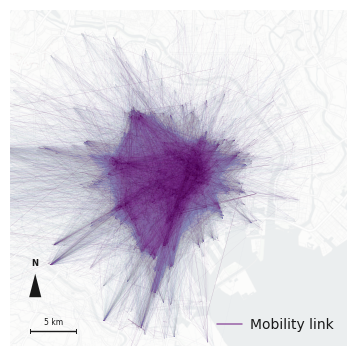

In [17]:

meeting_on_transaction_edges = prepare_top_edges(
    n_edges=100000,
    require_transaction_col=TRANSACTION_LINK_COL,
)
fig1_flow_map(
    meeting_on_transaction_edges,
    show_points=False,
    output_prefix="01c_tokyo_meeting_on_transaction_links_only",
    weight_col="mp_sum",
    edge_cmap=EDGE_CMAP,
    link_label="Mobility link",
)


Figure 1c

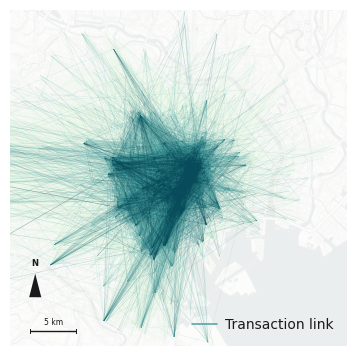

In [18]:

transaction_edges = prepare_transaction_edges(n_edges=50000)
fig1_flow_map(
    transaction_edges,
    show_points=False,
    output_prefix="02_tokyo_transaction_links_only",
    weight_col="trans_sum",
    edge_cmap=TRANS_EDGE_CMAP,
    link_label="Transaction link",
)

Figure 1d

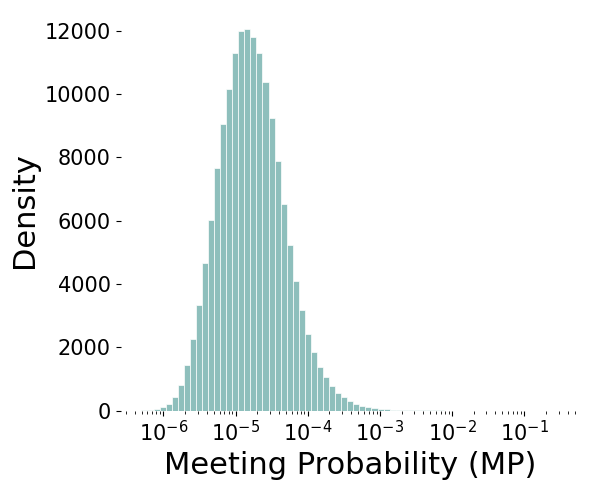

In [19]:

plt.rcdefaults()
df = pl.read_parquet(MP_PARQUET, columns=["MP"])
import numpy as np
import matplotlib.pyplot as plt

mp_nonzero = (
    df.filter(pl.col("MP") > 0)
    .get_column("MP")
    .to_numpy()
)

# log-spaced bins
bins = np.logspace(
    np.log10(mp_nonzero.min()),
    np.log10(mp_nonzero.max()),
    70
)

fig, ax = plt.subplots(figsize=(6, 5), dpi=100)

ax.hist(
    mp_nonzero,
    bins=bins,
    density=True,
    color="#72B0AB",
    alpha=0.8,
    edgecolor="white",
    linewidth=0.6,
)

ax.set_xscale("log")
ax.set_xlabel("Meeting Probability (MP)")

ax.set_xlabel("Meeting Probability (MP)", fontsize=22, fontfamily=FIGURE_FONT)
ax.set_ylabel("Density", fontsize=22, fontfamily=FIGURE_FONT)
ax.tick_params(axis="both", labelsize=15)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.tight_layout()
plt.show()

del df, mp_nonzero

In [20]:

from scipy import stats

plt.rcdefaults()
plt.rcParams.update({
    "font.size": 14,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def haversine(lat1, lon1, lat2, lon2):
    r = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


cell_cache = {}


def get_coord(cell):
    if cell not in cell_cache:
        cell_cache[cell] = (h3.cell_to_latlng(cell) if hasattr(h3, "cell_to_latlng")
                            else h3.h3_to_geo(cell))
    return cell_cache[cell]

Figure 1e

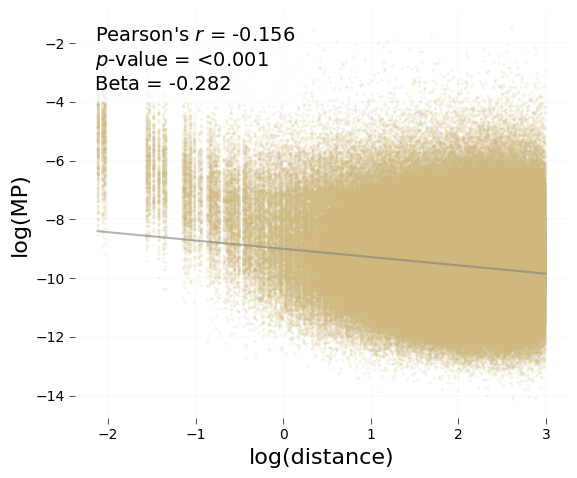

In [21]:

all_path = MP_PARQUET
scatter_color = "#CFB97E"
max_plot_points = 500_000
rng = np.random.default_rng(42)

plot_parts = []
n = 0
sum_x = 0.0
sum_y = 0.0
sum_xx = 0.0
sum_yy = 0.0
sum_xy = 0.0

all_data = pd.read_parquet(all_path, columns=["firm_i", "firm_j", "MP"])

for start in range(0, len(all_data), 500_000):
    chunk = all_data.iloc[start:start + 500_000].copy()
    coords_i = chunk["firm_i"].map(get_coord)
    coords_j = chunk["firm_j"].map(get_coord)

    lat_i = np.array([coord[0] for coord in coords_i])
    lon_i = np.array([coord[1] for coord in coords_i])
    lat_j = np.array([coord[0] for coord in coords_j])
    lon_j = np.array([coord[1] for coord in coords_j])

    dist = haversine(lat_i, lon_i, lat_j, lon_j)
    mp = chunk["MP"].to_numpy()
    valid = (dist > 0) & (dist <= 20) & (mp > 0)

    x = np.log(dist[valid])
    y = np.log(mp[valid])

    n_chunk = len(x)
    n += n_chunk
    sum_x += x.sum()
    sum_y += y.sum()
    sum_xx += np.dot(x, x)
    sum_yy += np.dot(y, y)
    sum_xy += np.dot(x, y)

    if n_chunk:
        keep = min(n_chunk, max_plot_points // 20)
        idx = rng.choice(n_chunk, size=keep, replace=False) if n_chunk > keep else np.arange(n_chunk)
        plot_parts.append(pd.DataFrame({"log_distance": x[idx], "log_mp": y[idx]}))

plot_df = pd.concat(plot_parts, ignore_index=True)
if len(plot_df) > max_plot_points:
    plot_df = plot_df.sample(max_plot_points, random_state=42)

sxx = sum_xx - (sum_x ** 2) / n
syy = sum_yy - (sum_y ** 2) / n
sxy = sum_xy - (sum_x * sum_y) / n
pearson_r = sxy / np.sqrt(sxx * syy)
slope = sxy / sxx
intercept = (sum_y - slope * sum_x) / n
beta = slope
t_stat = pearson_r * np.sqrt((n - 2) / (1 - pearson_r ** 2))
p_value = 2 * stats.t.sf(abs(t_stat), df=n - 2)

fig, ax = plt.subplots(figsize=(6, 5.0), dpi=100)
ax.scatter(
    plot_df["log_distance"],
    plot_df["log_mp"],
    s=5,
    alpha=0.15,
    color=scatter_color,
    edgecolors="none",
)

x_range = np.array([plot_df["log_distance"].min(), plot_df["log_distance"].max()])
ax.plot(x_range, intercept + slope * x_range, color="grey", linewidth=1.5, alpha=0.6)

p_value_str = "<0.001" if p_value < 0.001 else f"{p_value:.3f}"
ax.text(
    0.04,
    0.96,
    f"Pearson's $r$ = {pearson_r:.3f}\n"
    f"$p$-value = {p_value_str}\n"
    f"Beta = {beta:.3f}",
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=14,
    color="black",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="none", alpha=0.75),
)

ax.set_xlabel("log(distance)")
ax.set_ylabel("log(MP)")
ax.grid(True, linestyle="-", linewidth=0.3, alpha=0.2)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(labelsize=10, width=0.5, length=4)

plt.tight_layout()
plt.show()